<a href="https://colab.research.google.com/github/Shashank-sketchAl/ML-90-Day-Challenge-/blob/main/Day19.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Polynomial Regression

In [1]:
import pandas as pd

data = {
    "Experience": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "Salary": [25, 30, 38, 50, 65, 85, 110, 140, 175, 215]
}

df = pd.DataFrame(data)

print(df)

   Experience  Salary
0           1      25
1           2      30
2           3      38
3           4      50
4           5      65
5           6      85
6           7     110
7           8     140
8           9     175
9          10     215


In [2]:
X = df[["Experience"]]
y = df["Salary"]

print("Shape of X:",X.shape)
print("Shape of y:",y.shape)

Shape of X: (10, 1)
Shape of y: (10,)


In [3]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [4]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()
linear_model.fit(X,y)

linear_pred= linear_model.predict(X)

In [5]:
from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X)

print("Original X:")
print(X.head())

print("Polynomial X:")
print(X_poly[:5])

Original X:
   Experience
0           1
1           2
2           3
3           4
4           5
Polynomial X:
[[ 1.  1.  1.]
 [ 1.  2.  4.]
 [ 1.  3.  9.]
 [ 1.  4. 16.]
 [ 1.  5. 25.]]


In [6]:
poly_model = LinearRegression()
poly_model.fit(X_poly, y)

poly_pred = poly_model.predict(X_poly)

print("Polynomial predictions:")
print(poly_pred)

Polynomial predictions:
[ 26.52727273  29.40606061  36.76969697  48.61818182  64.95151515
  85.76969697 111.07272727 140.86060606 175.13333333 213.89090909]


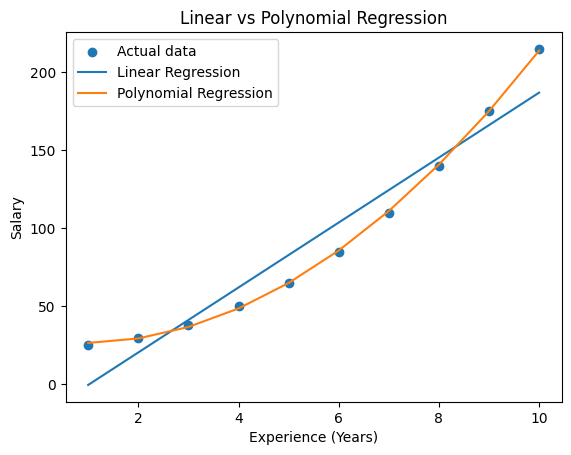

In [7]:
import matplotlib.pyplot as plt

plt.scatter(X["Experience"], y, label="Actual data")
plt.plot(X["Experience"], linear_pred, label="Linear Regression")
plt.plot(X["Experience"], poly_pred, label="Polynomial Regression")

plt.xlabel("Experience (Years)")
plt.ylabel("Salary")
plt.title("Linear vs Polynomial Regression")
plt.legend()
plt.show()

In [8]:
from sklearn.metrics import mean_absolute_error, r2_score

# Linear Regression metrics
linear_mae = mean_absolute_error(y, linear_pred)
linear_r2 = r2_score(y, linear_pred)

# Polynomial Regression metrics
poly_mae = mean_absolute_error(y, poly_pred)
poly_r2 = r2_score(y, poly_pred)

print("Linear Regression")
print("MAE:", linear_mae)
print("R2 Score:", linear_r2)

print("\nPolynomial Regression")
print("MAE:", poly_mae)
print("R2 Score:", poly_r2)

Linear Regression
MAE: 14.360000000000003
R2 Score: 0.9306385790960271

Polynomial Regression
MAE: 0.8727272727272819
R2 Score: 0.9997438209624019


Polynomial Regression was applied to model the nonlinear relationship between experience and salary. Using degree 2 polynomial features, it achieved an MAE of approximately 0.87 and an R² score of 0.9997 on the training dataset. It fit this curved pattern better than ordinary Linear Regression.